# OVM Homework Exercises I (WI3405TU)
### Carlo Dubbioso - Student number: 6858635

Run order: **Kernel → Restart & Run All** must finish without errors before submitting.
Figures are saved to `figures/` as PDF and used in the LaTeX report.

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

np.random.seed(42)  # fixed seed -> results reproduce the report
os.makedirs("figures", exist_ok=True)


def save_fig(name):
    """Save the current figure to figures/<name>.pdf."""
    plt.savefig(f"figures/{name}.pdf", bbox_inches="tight")


def mc_summary(X):
    """Return sample mean a_M, sample std b_M and 95% CI a_M +- 1.96 b_M / sqrt(M)."""
    M = len(X)
    a_M = X.mean()
    b_M = X.std(ddof=1)
    half = 1.96 * b_M / np.sqrt(M)
    return a_M, b_M, (a_M - half, a_M + half)


def qq_plot_normal(x, title=""):
    """Q-Q plot of x against N(mu_hat, sigma_hat^2)."""
    mu_hat, sigma_hat = x.mean(), x.std(ddof=1)
    stats.probplot(x, dist=stats.norm, sparams=(mu_hat, sigma_hat), plot=plt)
    plt.title(title)
    plt.xlabel(r"Theoretical quantiles $N(\hat\mu,\hat\sigma^2)$")
    plt.ylabel("Sample quantiles")
    plt.grid(True)

In [6]:
# pip install yfinance
import yfinance as yf

# Q1a: daily closes, 1 Sep 2025 - 31 Aug 2026 (end date is exclusive)
daily = yf.download("AAPL", start="2025-09-01", end="2026-09-01",
                    interval="1d", auto_adjust=False)
daily["Close"].to_csv("AAPL_daily.csv")

# Q1b: weekly closes, 2022-2025
weekly = yf.download("AAPL", start="2022-01-01", end="2026-01-01",
                     interval="1wk", auto_adjust=False)
weekly["Close"].to_csv("AAPL_weekly.csv")

print(len(daily), "daily rows,", len(weekly), "weekly rows")

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed

251 daily rows, 209 weekly rows


## Exercise 1: Market stock prices

### 1a. Prices and returns

In [7]:
# TODO: load daily close prices (1 Sep 2025 - 31 Aug 2026), file name = your CSV
# daily = pd.read_csv("AAPL_daily.csv", parse_dates=["Date"]).sort_values("Date")
# S = daily["Close"].to_numpy()

# TODO: simple return r_i = (S_i - S_{i-1}) / S_{i-1}
# TODO: log return  r_hat_i = ln(S_i / S_{i-1})
# TODO: plot prices, plot both returns, save_fig("ex1_prices"), save_fig("ex1_returns")

### 1b. Statistics (daily and weekly)

In [8]:
# TODO daily: histogram of log returns, mu_hat, sigma2_hat, Q-Q plot
# TODO weekly (2022-2025): same steps, compare Q-Q patterns
# save_fig("ex1_hist_daily"), save_fig("ex1_qq_daily"), save_fig("ex1_hist_weekly"), save_fig("ex1_qq_weekly")

## Exercise 2: Monte Carlo for E[1/sqrt(U)], U ~ U(0,1)

     M      a_M      b_M   CI_low  CI_high
   100 1.775799 1.258158 1.529200 2.022398
  1000 2.072746 2.631725 1.909630 2.235862
 10000 1.938813 2.136351 1.896940 1.980685
100000 2.007358 3.555913 1.985318 2.029398
        M       a_M       b_M    CI_low   CI_high
0     100  1.775799  1.258158  1.529200  2.022398
1    1000  2.072746  2.631725  1.909630  2.235862
2   10000  1.938813  2.136351  1.896940  1.980685
3  100000  2.007358  3.555913  1.985318  2.029398


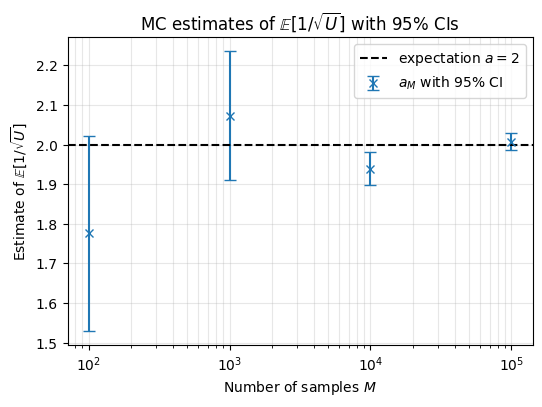

In [14]:
expectation = 2.0           # integral of u^(-1/2) on (0,1)
Ms = [10**2, 10**3, 10**4, 10**5]   # sample sizes
rows = []  

# for each M, sample U, X = 1/sqrt(U), call mc_summary(X)
for M in Ms:
    U = np.random.uniform(0, 1, size=M)   # M samples U_i ~ U(0,1)
    X = 1 / np.sqrt(U)                    # X_i = 1/sqrt(U_i)
    a_M, b_M, (ci_low, ci_high) = mc_summary(X)
    rows.append({
        "M": M,
        "a_M": a_M,
        "b_M": b_M,
        "CI_low": ci_low,
        "CI_high": ci_high,
    })

# build and print a DataFrame with the results 
results = pd.DataFrame(rows)
print(results.to_string(index=False))

# LaTeX rows to paste into Table \ref{tab:ex2}
print(results[["M", "a_M", "b_M", "CI_low", "CI_high"]])

# figure of estimates with CIs vs M (log x-axis), save_fig("ex2_estimates")
plt.figure(figsize=(6, 4))

# asymmetric error bars: distance from a_M down to CI_low and up to CI_high
yerr = [results["a_M"] - results["CI_low"],
        results["CI_high"] - results["a_M"]]

plt.errorbar(results["M"], results["a_M"], yerr=yerr,
             fmt="x", capsize=4, label=r"$a_M$ with 95% CI")
plt.axhline(expectation, color="k", linestyle="--", label=r"expectation $a = 2$")

plt.xscale("log")                      # M spans 10^2 ... 10^5
plt.xlabel("Number of samples $M$")
plt.ylabel(r"Estimate of $\mathbb{E}[1/\sqrt{U}]$")
plt.title(r"MC estimates of $\mathbb{E}[1/\sqrt{U}]$ with 95% CIs")
plt.legend()
plt.grid(True, which="both", alpha=0.3)

save_fig("ex2_estimates")
plt.show()

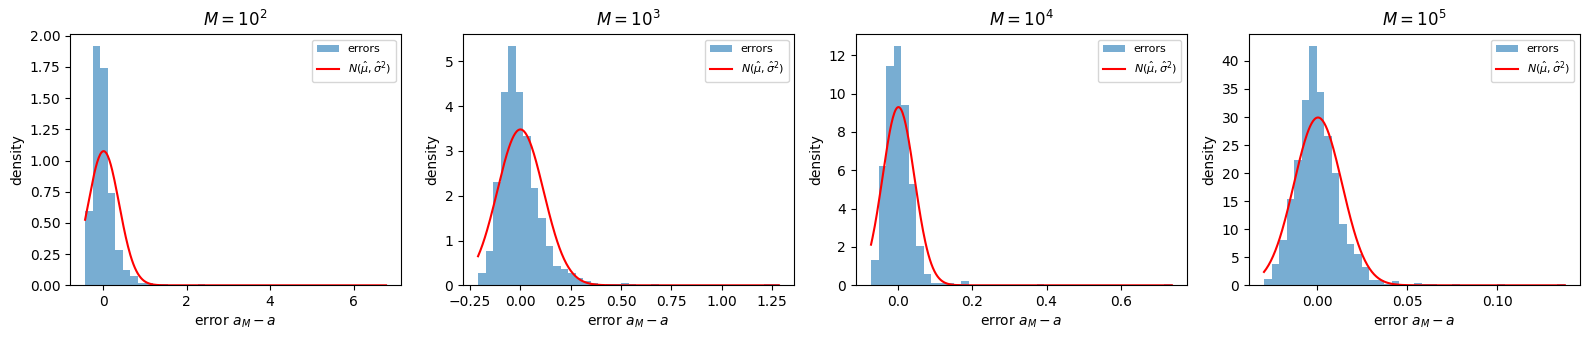

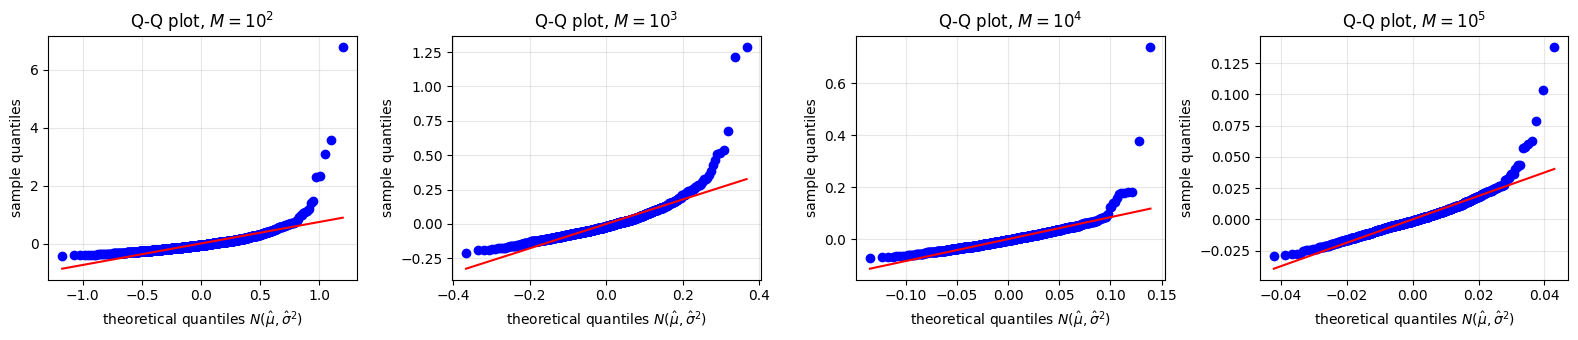

In [ ]:
# Normality of errors
# repeat the estimate K times for each M -> errors a_M - expectation
# histogram + normal density with estimated parameters, Q-Q plot

K = 1000    # number of independent MC runs per M
errors = {} # errors[M] = array of K errors a_M - a

for M in Ms:
    a_M_runs = np.empty(K)
    for k in range(K):
        U = 1 - np.random.uniform(0, 1, size=M)
        a_M_runs[k] = (1 / np.sqrt(U)).mean()
    errors[M] = a_M_runs - expectation

# Histogram + fitted normal density 
fig, axes = plt.subplots(1, len(Ms), figsize=(16, 3.5))
for ax, M in zip(axes, Ms):
    e = errors[M]
    mu_hat, sigma_hat = e.mean(), e.std(ddof=1)
    ax.hist(e, bins=40, density=True, alpha=0.6, label="errors")
    x = np.linspace(e.min(), e.max(), 400)
    ax.plot(x, stats.norm.pdf(x, mu_hat, sigma_hat), "r-",
            label=r"$N(\hat\mu,\hat\sigma^2)$")
    ax.set_title(f"$M = 10^{{{int(np.log10(M))}}}$")
    ax.set_xlabel(r"error $a_M - a$")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig("ex2_hist")
plt.show()

# Q-Q plots 
fig, axes = plt.subplots(1, len(Ms), figsize=(16, 3.5))
for ax, M in zip(axes, Ms):
    e = errors[M]
    stats.probplot(e, dist=stats.norm,
                   sparams=(e.mean(), e.std(ddof=1)), plot=ax)
    ax.set_title(f"Q-Q plot, $M = 10^{{{int(np.log10(M))}}}$")
    ax.set_xlabel(r"theoretical quantiles $N(\hat\mu,\hat\sigma^2)$")
    ax.set_ylabel("sample quantiles")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
save_fig("ex2_qq")
plt.show()

## Exercise 3: Simulation of stock price paths
Parameters: T = 1, S0 = 170, sigma = 0.344, mu = 0.1.

In [9]:
T, S0, sigma, mu = 1.0, 170.0, 0.344, 0.1
M = 5000

### 3a. Discrete model vs continuous-time model

In [ ]:
# TODO: L = 5, one path, plot S(t_i), t_i = i * dt, dt = T / L
# TODO: M paths, store S_T, histogram
# TODO: repeat for L = 10, 20, 50, 100
# TODO: ECDFs for all L + theoretical CDF of S_T = S0 exp((mu - sigma^2/2) T + sigma sqrt(T) Z) in one figure
# save_fig("ex3_path"), save_fig("ex3_hist"), save_fig("ex3_ecdf")

### 3b. Standard MC vs antithetic variates for E[S(T)]

In [ ]:
exact_ST = S0 * np.exp(mu * T)
Ms = [10**2, 10**3, 10**4, 10**5]

# TODO: standard MC and antithetic estimator (X(Z) + X(-Z)) / 2
# TODO: 95% CIs, widths I_M and I_M^A, ratio I_M / I_M^A
# TODO: table (a_M, b_M, CI, width, ratio) next to exact_ST

## Exercise 4: Historical volatility

In [ ]:
# 4a: TODO sample volatility of daily and weekly log returns (state if annualised)

# 4b: TODO EWMA with w = 0.94, initial sigma* from the first 20 observations
# w = 0.94
# plot daily and weekly EWMA volatility (cf. Figure 20.1)
# save_fig("ex4_ewma_daily"), save_fig("ex4_ewma_weekly")

## Exercise 5: Binomial method
Parameters: S0 = 1, T = 3, mu = r = 0.05, sigma = 0.3, E = 1.5, M = 12.

In [ ]:
S0, T, r, sigma, E = 1.0, 3.0, 0.05, 0.3, 1.5
M = 12
dt = T / M
# TODO: u, d, p (risk-neutral), discount factor exp(-r * dt)

In [ ]:
# 5a: TODO fixed strike lookback put, payoff max(E - S_min, 0)
# recombining tree loses path information -> track the minimum

In [ ]:
# 5b: TODO shout put, backward induction
# V = max(shout value, continuation value)